# Calcul du temps total de trajet avec les données GTFS SNCF

Calculer la durée totale d'un trajet avec les données GTFS de la SNCF, en se basant sur les champs `arrival_time` et `departure_time`.

## 1. Chargement des données GTFS

In [128]:
import pandas as pd
from datetime import timedelta
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
sns.set_style('whitegrid')

# Définir le chemin vers les données GTFS
GTFS_PATH = Path("/home/valentin/T-AIA-911-NAN_1/dataset/sncf")

# Chargement des fichiers GTFS
try:
    stop_times = pd.read_csv(GTFS_PATH / "stop_times.txt")
    trips = pd.read_csv(GTFS_PATH / "trips.txt")
    stops = pd.read_csv(GTFS_PATH / "stops.txt")
    routes = pd.read_csv(GTFS_PATH / "routes.txt")
    
    print(f"stop_times.txt : {len(stop_times)} enregistrements")
    print(f"trips.txt : {len(trips)} enregistrements")
    print(f"stops.txt : {len(stops)} enregistrements")
    print(f"routes.txt : {len(routes)} enregistrements")
    
except FileNotFoundError as e:
    print(f"Erreur : Fichier non trouvé - {e}")

print("\n" + "=" * 80 + "\n")

# Aperçu des données stop_times
print("Aperçu de stop_times.txt :")
print(stop_times.head())
print("\nColonnes disponibles :", stop_times.columns.tolist())

stop_times.txt : 397900 enregistrements
trips.txt : 46910 enregistrements
stops.txt : 8899 enregistrements
routes.txt : 839 enregistrements


Aperçu de stop_times.txt :
                                             trip_id arrival_time  \
0  OCESN105241F1187_F:NAV:FR:Line::85d3579c-996b-...     19:54:00   
1  OCESN105241F1187_F:NAV:FR:Line::85d3579c-996b-...     19:59:00   
2  OCESN105342F1187_F:NAV:FR:Line::85d3579c-996b-...     17:22:00   
3  OCESN105342F1187_F:NAV:FR:Line::85d3579c-996b-...     17:27:00   
4  OCESN105342F1187_F:NAV:FR:Line::85d3579c-996b-...     17:33:00   

  departure_time                        stop_id  stop_sequence  stop_headsign  \
0       19:54:00  StopPoint:OCENavette-87571000              0            NaN   
1       19:59:00  StopPoint:OCENavette-87571240              1            NaN   
2       17:22:00  StopPoint:OCENavette-87571240              0            NaN   
3       17:27:00  StopPoint:OCENavette-87571000              1            NaN   
4       17:

## 3. Parsing du format temporel GTFS

Les temps GTFS sont au format HH:MM:SS et peuvent dépasser 24 heures (ex: 25:30:00 pour 01h30 le lendemain). Nous créons des fonctions pour gérer ce format spécifique.

In [129]:
def parse_gtfs_time(time_str):
    """
    Convertit un temps GTFS (HH:MM:SS) en timedelta.
    Gère les heures > 24 (ex: 25:30:00 = 1j 1h30)
    
    Args:
        time_str: String au format HH:MM:SS
    
    Returns:
        timedelta object
    """
    if pd.isna(time_str):
        return None
    
    try:
        hours, minutes, seconds = map(int, str(time_str).split(':'))
        return timedelta(hours=hours, minutes=minutes, seconds=seconds)
    except Exception as e:
        print(f"Erreur de parsing pour '{time_str}': {e}")
        return None

def timedelta_to_hours(td):
    """
    Convertit un timedelta en nombre d'heures (float)
    
    Args:
        td: timedelta object
    
    Returns:
        float: nombre d'heures
    """
    if td is None or pd.isna(td):
        return None
    return td.total_seconds() / 3600

def format_duration(td):
    """
    Formate un timedelta en string lisible (XhYYmin)
    
    Args:
        td: timedelta object
    
    Returns:
        string: durée formatée
    """
    if td is None or pd.isna(td):
        return "N/A"
    
    total_seconds = int(td.total_seconds())
    hours = total_seconds // 3600
    minutes = (total_seconds % 3600) // 60
    
    if hours > 0:
        return f"{hours}h{minutes:02d}min"
    else:
        return f"{minutes}min"

# Test des fonctions
test_times = ["08:30:00", "14:45:30", "25:15:00", "26:00:00"]
print("Tests de parsing :")
for time_str in test_times:
    td = parse_gtfs_time(time_str)
    print(f"  {time_str} => {td} => {format_duration(td)}")

print("\n" + "=" * 80 + "\n")

# Application du parsing sur les colonnes de temps
print("Conversion des temps GTFS...")

stop_times['departure_td'] = stop_times['departure_time'].apply(parse_gtfs_time)
stop_times['arrival_td'] = stop_times['arrival_time'].apply(parse_gtfs_time)

print("Conversion terminée!")
print(f"\nAperçu des données converties :")
print(stop_times[['trip_id', 'stop_sequence', 'departure_time', 'departure_td', 'arrival_time', 'arrival_td']].head(10))

Tests de parsing :
  08:30:00 => 8:30:00 => 8h30min
  14:45:30 => 14:45:30 => 14h45min
  25:15:00 => 1 day, 1:15:00 => 25h15min
  26:00:00 => 1 day, 2:00:00 => 26h00min


Conversion des temps GTFS...
Conversion terminée!

Aperçu des données converties :
                                             trip_id  stop_sequence  \
0  OCESN105241F1187_F:NAV:FR:Line::85d3579c-996b-...              0   
1  OCESN105241F1187_F:NAV:FR:Line::85d3579c-996b-...              1   
2  OCESN105342F1187_F:NAV:FR:Line::85d3579c-996b-...              0   
3  OCESN105342F1187_F:NAV:FR:Line::85d3579c-996b-...              1   
4  OCESN105342F1187_F:NAV:FR:Line::85d3579c-996b-...              0   
5  OCESN105342F1187_F:NAV:FR:Line::85d3579c-996b-...              1   
6  OCESN105342F1187_F:NAV:FR:Line::85d3579c-996b-...              0   
7  OCESN105342F1187_F:NAV:FR:Line::85d3579c-996b-...              1   
8  OCESN105347F1187_F:NAV:FR:Line::85d3579c-996b-...              0   
9  OCESN105347F1187_F:NAV:FR:Line::8

## 4. Calcul de la durée totale des trajets

Pour chaque trajet (trip_id), nous calculons la durée entre le premier départ et la dernière arrivée.

In [130]:
def calculate_trip_duration(trip_id, stop_times_df):
    """
    Calcule la durée totale d'un trajet
    
    Args:
        trip_id: ID du trajet
        stop_times_df: DataFrame des stop_times
    
    Returns:
        dict avec les informations du trajet
    """
    trip_stops = stop_times_df[stop_times_df['trip_id'] == trip_id].sort_values('stop_sequence')
    
    if len(trip_stops) < 2:
        return None
    
    first_stop = trip_stops.iloc[0]
    last_stop = trip_stops.iloc[-1]
    
    departure = first_stop['departure_td']
    arrival = last_stop['arrival_td']
    
    if departure is None or arrival is None:
        return None
    
    duration = arrival - departure
    
    return {
        'trip_id': trip_id,
        'first_stop_id': first_stop['stop_id'],
        'last_stop_id': last_stop['stop_id'],
        'departure_time': first_stop['departure_time'],
        'arrival_time': last_stop['arrival_time'],
        'duration': duration,
        'duration_hours': timedelta_to_hours(duration),
        'duration_formatted': format_duration(duration),
        'num_stops': len(trip_stops)
    }

# Calcul des durées pour tous les trajets
print("Calcul des durées de trajet...")

trip_ids = stop_times['trip_id'].unique()
print(f"Nombre de trajets à analyser : {len(trip_ids)}")

# Calcul pour un échantillon (limité pour la performance)
sample_size = min(1000, len(trip_ids))
trip_durations = []

for i, trip_id in enumerate(trip_ids[:sample_size]):
    if i % 200 == 0:
        print(f"  Traitement : {i}/{sample_size}")
    
    result = calculate_trip_duration(trip_id, stop_times)
    if result:
        trip_durations.append(result)

trip_durations_df = pd.DataFrame(trip_durations)
print(f"\n{len(trip_durations_df)} trajets analysés avec succès!")

print("\n" + "=" * 80 + "\n")

# Affichage des statistiques de durée
print("Statistiques des durées de trajet :")
print(trip_durations_df['duration_hours'].describe())

print("\n10 trajets les plus longs :")
print(trip_durations_df.nlargest(10, 'duration_hours')[
    ['trip_id', 'departure_time', 'arrival_time', 'duration_formatted', 'num_stops']
])

print("\n10 trajets les plus courts :")
print(trip_durations_df.nsmallest(10, 'duration_hours')[
    ['trip_id', 'departure_time', 'arrival_time', 'duration_formatted', 'num_stops']
])

Calcul des durées de trajet...
Nombre de trajets à analyser : 46910
  Traitement : 0/1000
  Traitement : 200/1000
  Traitement : 400/1000
  Traitement : 600/1000
  Traitement : 800/1000

1000 trajets analysés avec succès!


Statistiques des durées de trajet :
count    1000.000000
mean        3.004617
std         2.140481
min         0.083333
25%         1.766667
50%         2.266667
75%         4.570833
max        11.116667
Name: duration_hours, dtype: float64

10 trajets les plus longs :
                                               trip_id departure_time  \
297  OCESN12177F1187_F:OUI:FR:Line::19ea029b-6782-4...       11:36:00   
293  OCESN12177F1187_F:OUI:FR:Line::19ea029b-6782-4...       12:00:00   
291  OCESN12177F1187_F:OUI:FR:Line::19ea029b-6782-4...       12:26:00   
292  OCESN12177F1187_F:OUI:FR:Line::19ea029b-6782-4...       12:26:00   
294  OCESN12177F1187_F:OUI:FR:Line::19ea029b-6782-4...       12:26:00   
262  OCESN12176F1187_F:OUI:FR:Line::19ea029b-6782-4...       06:57:0

## 5. Filtrage et sélection de routes

Enrichissement des données avec les informations les noms des stations

In [131]:
# Enrichissement avec les noms de stations
trip_durations_enriched = trip_durations_df.merge(
    stops[['stop_id', 'stop_name']], 
    left_on='first_stop_id', 
    right_on='stop_id', 
    how='left'
).rename(columns={'stop_name': 'origin_name'})

trip_durations_enriched = trip_durations_enriched.merge(
    stops[['stop_id', 'stop_name']], 
    left_on='last_stop_id', 
    right_on='stop_id', 
    how='left'
).rename(columns={'stop_name': 'destination_name'})

# Nettoyage
trip_durations_enriched = trip_durations_enriched.drop(['stop_id_x', 'stop_id_y'], axis=1)

print("Aperçu des trajets enrichis :")
print(trip_durations_enriched[['origin_name', 'destination_name', 'departure_time', 'arrival_time', 'duration_formatted', 'num_stops']].head(10))

print("\n" + "=" * 80 + "\n")

# Fonction de recherche de trajets
def search_trips(origin_pattern, destination_pattern, df):
    """
    Recherche des trajets par origine et destination
    
    Args:
        origin_pattern: motif pour l'origine (ex: "Paris")
        destination_pattern: motif pour la destination (ex: "Lyon")
        df: DataFrame des trajets
    
    Returns:
        DataFrame filtré
    """
    mask = (
        df['origin_name'].str.contains(origin_pattern, case=False, na=False) &
        df['destination_name'].str.contains(destination_pattern, case=False, na=False)
    )
    
    results = df[mask].copy()
    results = results.sort_values('duration_hours')
    
    return results

# Affichage des stations les plus fréquentes
print("Top 10 des origines :")
print(trip_durations_enriched['origin_name'].value_counts().head(10))

print("\nTop 10 des destinations :")
print(trip_durations_enriched['destination_name'].value_counts().head(10))

Aperçu des trajets enrichis :
              origin_name        destination_name departure_time arrival_time  \
0                   Tours  Saint-Pierre-des-Corps       19:54:00     19:59:00   
1  Saint-Pierre-des-Corps                   Tours       17:22:00     17:27:00   
2  Saint-Pierre-des-Corps                   Tours       17:33:00     17:38:00   
3  Saint-Pierre-des-Corps                   Tours       17:23:00     17:28:00   
4  Saint-Pierre-des-Corps                   Tours       22:10:00     22:15:00   
5  Saint-Pierre-des-Corps                   Tours       05:55:00     06:00:00   
6  Saint-Pierre-des-Corps                   Tours       10:40:00     10:46:00   
7  Saint-Pierre-des-Corps                   Tours       10:44:00     10:49:00   
8  Saint-Pierre-des-Corps                   Tours       11:12:00     11:18:00   
9  Saint-Pierre-des-Corps                   Tours       10:40:00     10:45:00   

  duration_formatted  num_stops  
0               5min          2  
1         

## 6. Visualisation des résultats

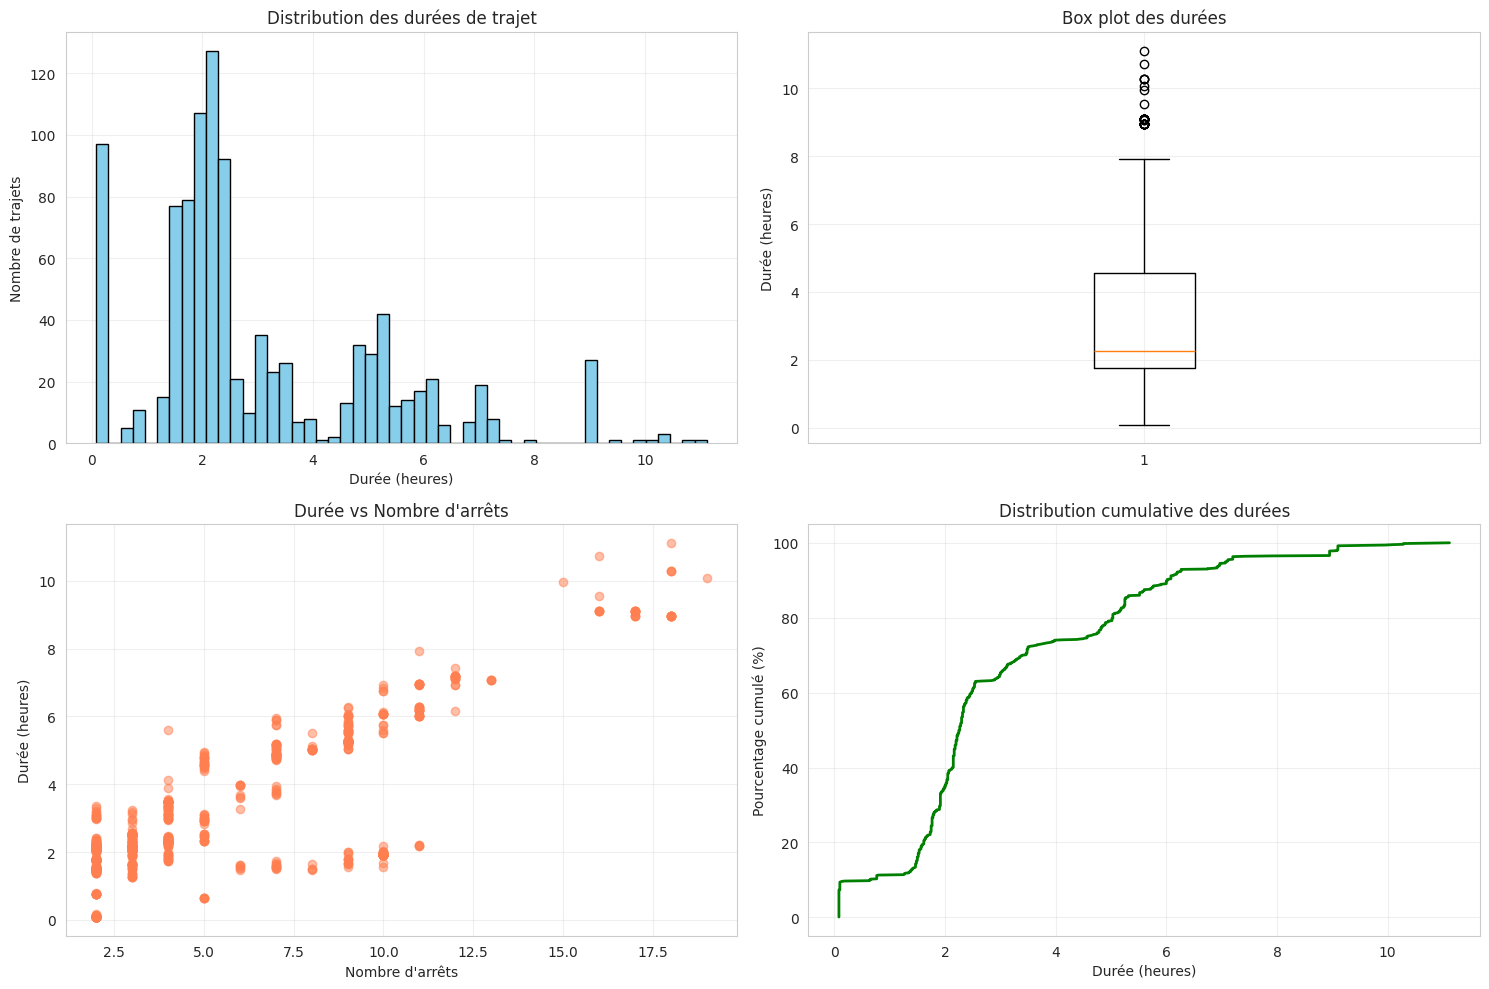


Statistiques clés :
Durée moyenne : 3.00h
Durée médiane : 2.27h
Durée min : 0.08h
Durée max : 11.12h


In [132]:
# Distribution des durées de trajet
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Histogramme des durées
axes[0, 0].hist(trip_durations_df['duration_hours'], bins=50, color='skyblue', edgecolor='black')
axes[0, 0].set_xlabel('Durée (heures)')
axes[0, 0].set_ylabel('Nombre de trajets')
axes[0, 0].set_title('Distribution des durées de trajet')
axes[0, 0].grid(True, alpha=0.3)

# Box plot des durées
axes[0, 1].boxplot(trip_durations_df['duration_hours'].dropna())
axes[0, 1].set_ylabel('Durée (heures)')
axes[0, 1].set_title('Box plot des durées')
axes[0, 1].grid(True, alpha=0.3)

# Relation durée vs nombre d'arrêts
axes[1, 0].scatter(trip_durations_df['num_stops'], trip_durations_df['duration_hours'], alpha=0.5, color='coral')
axes[1, 0].set_xlabel('Nombre d\'arrêts')
axes[1, 0].set_ylabel('Durée (heures)')
axes[1, 0].set_title('Durée vs Nombre d\'arrêts')
axes[1, 0].grid(True, alpha=0.3)

# Distribution cumulative
sorted_durations = np.sort(trip_durations_df['duration_hours'].dropna())
cumulative = np.arange(1, len(sorted_durations) + 1) / len(sorted_durations) * 100
axes[1, 1].plot(sorted_durations, cumulative, color='green', linewidth=2)
axes[1, 1].set_xlabel('Durée (heures)')
axes[1, 1].set_ylabel('Pourcentage cumulé (%)')
axes[1, 1].set_title('Distribution cumulative des durées')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nStatistiques clés :")
print(f"Durée moyenne : {trip_durations_df['duration_hours'].mean():.2f}h")
print(f"Durée médiane : {trip_durations_df['duration_hours'].median():.2f}h")
print(f"Durée min : {trip_durations_df['duration_hours'].min():.2f}h")
print(f"Durée max : {trip_durations_df['duration_hours'].max():.2f}h")

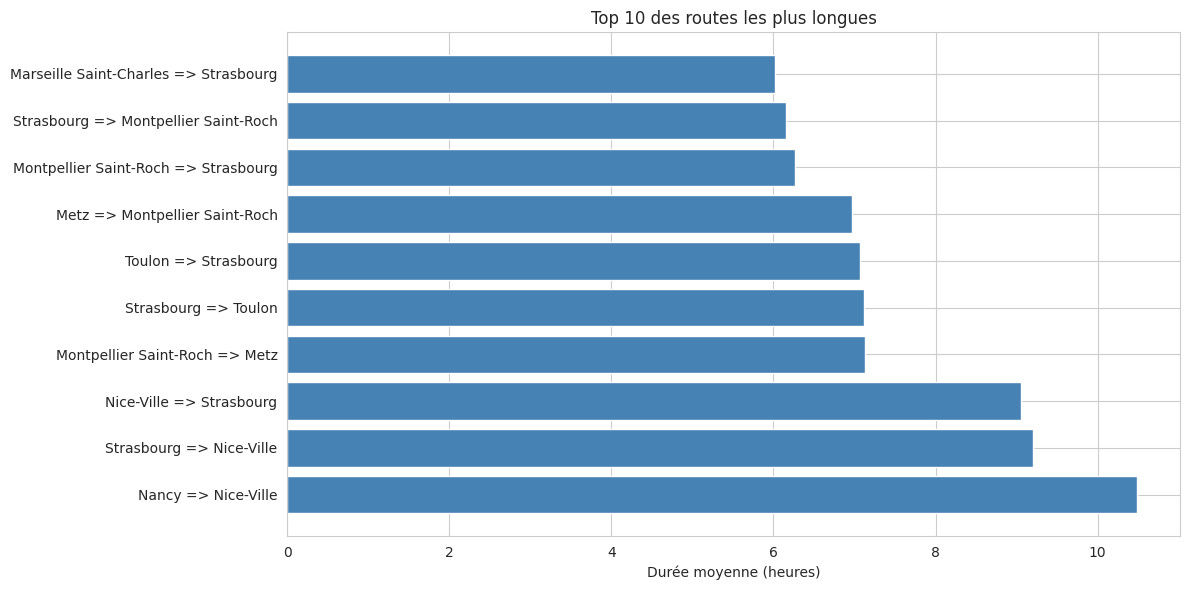


Top 10 des routes les plus longues :
                                    route  duration_mean  count
35                    Nancy => Nice-Ville      10.491667      4
74               Strasbourg => Nice-Ville       9.205556     15
40               Nice-Ville => Strasbourg       9.056667     15
29         Montpellier Saint-Roch => Metz       7.131250     16
76                   Strasbourg => Toulon       7.112500      4
78                   Toulon => Strasbourg       7.066667      4
24         Metz => Montpellier Saint-Roch       6.966667      4
32   Montpellier Saint-Roch => Strasbourg       6.266667      5
73   Strasbourg => Montpellier Saint-Roch       6.160000     10
22  Marseille Saint-Charles => Strasbourg       6.014583     16


In [133]:
# Top 10 des routes par durée moyenne (si suffisamment de données)
if 'origin_name' in trip_durations_enriched.columns:
    trip_durations_enriched['route'] = (trip_durations_enriched['origin_name'] + ' => ' + trip_durations_enriched['destination_name'])
    
    route_stats = trip_durations_enriched.groupby('route').agg({
        'duration_hours': ['mean', 'count']
    }).reset_index()
    
    route_stats.columns = ['route', 'duration_mean', 'count']
    route_stats = route_stats[route_stats['count'] >= 3]  # Au moins 3 trajets
    
    if len(route_stats) > 0:
        top_routes = route_stats.nlargest(10, 'duration_mean')
        
        plt.figure(figsize=(12, 6))
        plt.barh(range(len(top_routes)), top_routes['duration_mean'], color='steelblue')
        plt.yticks(range(len(top_routes)), top_routes['route'])
        plt.xlabel('Durée moyenne (heures)')
        plt.title('Top 10 des routes les plus longues')
        plt.tight_layout()
        plt.show()
        
        print("\nTop 10 des routes les plus longues :")
        print(top_routes)

## 7. Exemple trajet : Paris Montparnasse → Nantes

Analyse trajet entre Paris Montparnasse et Nantes avec :
- Le temps total
- Les temps d'attente à chaque arrêt
- Le temps de trajet entre chaque arrêt

In [134]:
# Recherche des trajets Paris Montparnasse → Nantes
print("Recherche des trajets Paris Montparnasse => Nantes...\n")

# Recherche dans les données enrichies
paris_nantes = search_trips("Montparnasse", "Nantes", trip_durations_enriched)

if len(paris_nantes) > 0:
    print(f"{len(paris_nantes)} trajet(s) trouvé(s)\n")
    print("Liste des trajets :")
    print(paris_nantes[['trip_id', 'origin_name', 'destination_name', 'departure_time', 'arrival_time', 'duration_formatted', 'num_stops']].to_string(index=False))
    
    # Sélection du premier trajet pour l'analyse détaillée
    selected_trip_id = paris_nantes.iloc[0]['trip_id']
    print(f"\nSélection du trajet {selected_trip_id} pour l'analyse détaillée")
else:
    print("Aucun trajet trouvé entre Paris Montparnasse et Nantes")
    print("\nRecherche plus large (Paris → Nantes)...")
    paris_nantes = search_trips("Paris", "Nantes", trip_durations_enriched)
    
    if len(paris_nantes) > 0:
        print(f"{len(paris_nantes)} trajet(s) trouvé(s)\n")
        print(paris_nantes[['trip_id', 'origin_name', 'destination_name', 'departure_time', 'arrival_time', 'duration_formatted']].head(10))
        selected_trip_id = paris_nantes.iloc[0]['trip_id']
        print(f"\nSélection du trajet {selected_trip_id} pour l'analyse détaillée")
    else:
        print("Aucun trajet trouvé. Vérifiez les données GTFS.")
        selected_trip_id = None

Recherche des trajets Paris Montparnasse => Nantes...

33 trajet(s) trouvé(s)

Liste des trajets :
                                                                                               trip_id                   origin_name destination_name departure_time arrival_time duration_formatted  num_stops
OCESN12467F1187_F:OUI:FR:Line::62C16406-4390-4C30-B97A-94317527CF00::87391003:87481002:3:1254:20260713 Paris Montparnasse Hall 1 - 2           Nantes       10:52:00     12:54:00            2h02min          3
OCESN12467F1187_F:OUI:FR:Line::62C16406-4390-4C30-B97A-94317527CF00::87391003:87481002:3:1254:20260725 Paris Montparnasse Hall 1 - 2           Nantes       10:52:00     12:54:00            2h02min          3
OCESN12467F1187_F:OUI:FR:Line::62C16406-4390-4C30-B97A-94317527CF00::87391003:87481002:3:1254:20260627 Paris Montparnasse Hall 1 - 2           Nantes       10:52:00     12:54:00            2h02min          3
OCESN12467F1187_F:OUI:FR:Line::62C16406-4390-4C30-B97A-94317527CF00::

In [135]:
# Analyse détaillée du trajet sélectionné
if selected_trip_id is not None:
    # Récupération de tous les arrêts du trajet
    trip_stops_detailed = stop_times[stop_times['trip_id'] == selected_trip_id].sort_values('stop_sequence').copy()
    
    # Enrichissement avec les noms de stations
    trip_stops_detailed = trip_stops_detailed.merge(
        stops[['stop_id', 'stop_name']], 
        on='stop_id', 
        how='left'
    )
    
    print("=" * 80)
    print(f"ANALYSE DÉTAILLÉE DU TRAJET {selected_trip_id}")
    print("=" * 80)
    
    # Informations générales
    first_departure = trip_stops_detailed.iloc[0]['departure_time']
    last_arrival = trip_stops_detailed.iloc[-1]['arrival_time']
    
    first_departure_td = parse_gtfs_time(first_departure)
    last_arrival_td = parse_gtfs_time(last_arrival)
    total_duration = last_arrival_td - first_departure_td
    
    print(f"\nOrigine : {trip_stops_detailed.iloc[0]['stop_name']}")
    print(f"Destination : {trip_stops_detailed.iloc[-1]['stop_name']}")
    print(f"Départ : {first_departure}")
    print(f"Arrivée : {last_arrival}")
    print(f"DURÉE TOTALE : {format_duration(total_duration)} ({total_duration})")
    print(f"Nombre d'arrêts : {len(trip_stops_detailed)}")
    
    # Calcul des temps d'attente et temps de trajet entre arrêts
    print("\n" + "=" * 80)
    print("DÉTAIL DES ARRÊTS ET TEMPS D'ATTENTE")
    print("=" * 80)
    
    total_wait_time = timedelta(0)
    total_travel_time = timedelta(0)
    
    for idx, row in trip_stops_detailed.iterrows():
        seq = row['stop_sequence']
        stop_name = row['stop_name']
        arrival = row['arrival_time']
        departure = row['departure_time']
        
        arrival_td = parse_gtfs_time(arrival)
        departure_td = parse_gtfs_time(departure)
        
        # Temps d'attente à cet arrêt
        if arrival_td and departure_td:
            wait_time = departure_td - arrival_td
        else:
            wait_time = timedelta(0)
        
        total_wait_time += wait_time
        
        print(f"\n{seq}. {stop_name}")
        print(f"Arrivée : {arrival}")
        print(f"Départ : {departure}")
        print(f"Attente : {format_duration(wait_time)}")
        
        # Temps de trajet jusqu'au prochain arrêt
        if seq < trip_stops_detailed['stop_sequence'].max():
            next_row = trip_stops_detailed[trip_stops_detailed['stop_sequence'] == seq + 1].iloc[0]
            next_arrival_td = parse_gtfs_time(next_row['arrival_time'])
            
            if departure_td and next_arrival_td:
                travel_time = next_arrival_td - departure_td
                total_travel_time += travel_time
                print(f"Trajet vers prochain arrêt : {format_duration(travel_time)}")
    
    # Résumé
    print("\n" + "=" * 80)
    print("RÉSUMÉ")
    print("=" * 80)
    print(f"Durée totale du trajet : {format_duration(total_duration)}")
    print(f"Temps en mouvement : {format_duration(total_travel_time)}")
    print(f"Temps d'attente total : {format_duration(total_wait_time)}")
    print(f"Pourcentage d'attente : {(total_wait_time.total_seconds() / total_duration.total_seconds() * 100):.1f}%")
    
else:
    print("Impossible d'effectuer l'analyse détaillée : aucun trajet sélectionné.")

ANALYSE DÉTAILLÉE DU TRAJET OCESN12467F1187_F:OUI:FR:Line::62C16406-4390-4C30-B97A-94317527CF00::87391003:87481002:3:1254:20260713

Origine : Paris Montparnasse Hall 1 - 2
Destination : Nantes
Départ : 10:52:00
Arrivée : 12:54:00
DURÉE TOTALE : 2h02min (2:02:00)
Nombre d'arrêts : 3

DÉTAIL DES ARRÊTS ET TEMPS D'ATTENTE

0. Paris Montparnasse Hall 1 - 2
Arrivée : 10:52:00
Départ : 10:52:00
Attente : 0min
Trajet vers prochain arrêt : 1h22min

1. Angers Saint-Laud
Arrivée : 12:14:00
Départ : 12:17:00
Attente : 3min
Trajet vers prochain arrêt : 37min

2. Nantes
Arrivée : 12:54:00
Départ : 12:54:00
Attente : 0min

RÉSUMÉ
Durée totale du trajet : 2h02min
Temps en mouvement : 1h59min
Temps d'attente total : 3min
Pourcentage d'attente : 2.5%


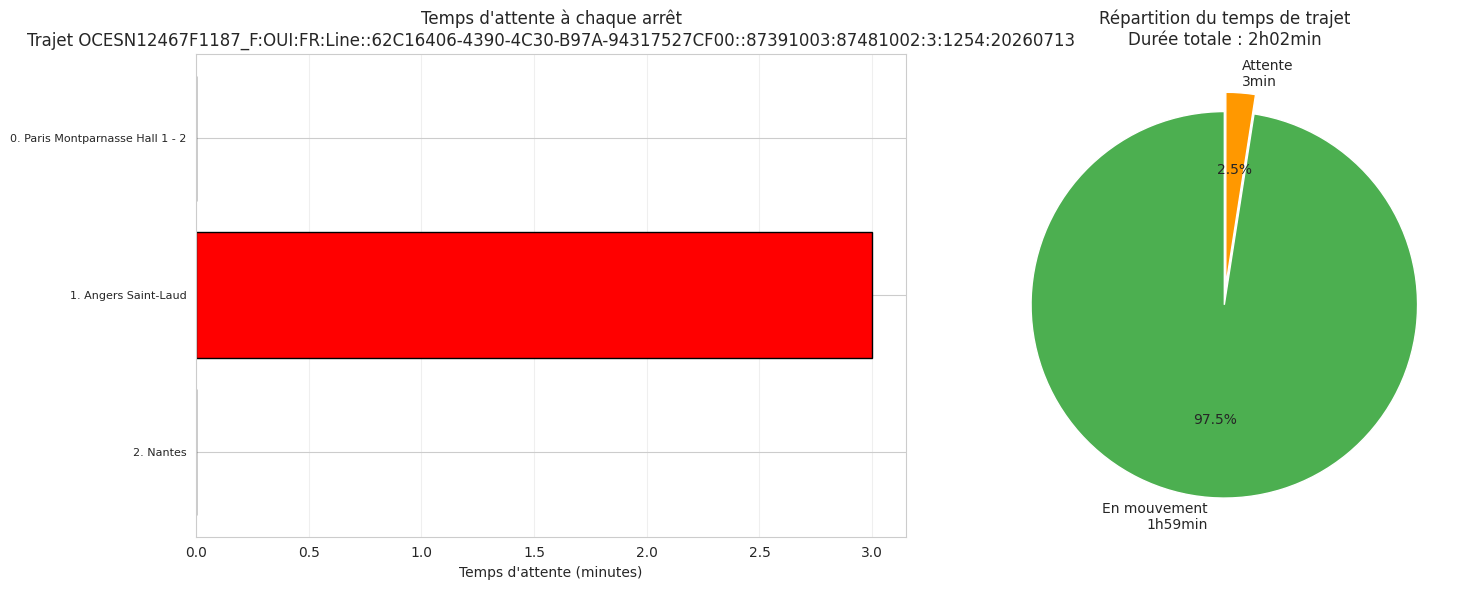


Note : Les arrêts avec temps d'attente > 2 min sont en rouge


In [136]:
# Visualisation des temps d'attente par arrêt
if selected_trip_id is not None:
    # Préparation des données pour la visualisation
    wait_times = []
    stop_names_short = []
    
    for idx, row in trip_stops_detailed.iterrows():
        arrival_td = parse_gtfs_time(row['arrival_time'])
        departure_td = parse_gtfs_time(row['departure_time'])
        
        if arrival_td and departure_td:
            wait_time_minutes = (departure_td - arrival_td).total_seconds() / 60
            wait_times.append(wait_time_minutes)
            
            # Raccourcir les noms trop longs
            stop_name = row['stop_name']
            if len(stop_name) > 30:
                stop_name = stop_name[:27] + "..."
            stop_names_short.append(f"{row['stop_sequence']}. {stop_name}")
    
    # Création de la visualisation
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Graphique 1 : Temps d'attente par arrêt
    colors = ['red' if wt > 2 else 'lightblue' for wt in wait_times]
    axes[0].barh(range(len(wait_times)), wait_times, color=colors, edgecolor='black')
    axes[0].set_yticks(range(len(stop_names_short)))
    axes[0].set_yticklabels(stop_names_short, fontsize=8)
    axes[0].set_xlabel('Temps d\'attente (minutes)')
    axes[0].set_title(f'Temps d\'attente à chaque arrêt\nTrajet {selected_trip_id}')
    axes[0].grid(True, alpha=0.3, axis='x')
    axes[0].invert_yaxis()
    
    # Graphique 2 : Répartition du temps
    total_dur_sec = total_duration.total_seconds()
    travel_sec = total_travel_time.total_seconds()
    wait_sec = total_wait_time.total_seconds()
    
    sizes = [travel_sec, wait_sec]
    labels = [f'En mouvement\n{format_duration(total_travel_time)}', f'Attente\n{format_duration(total_wait_time)}']
    colors_pie = ['#4CAF50', '#FF9800']
    explode = (0.05, 0.05)
    
    axes[1].pie(sizes, labels=labels, colors=colors_pie, autopct='%1.1f%%', startangle=90, explode=explode, textprops={'fontsize': 10})
    axes[1].set_title(f'Répartition du temps de trajet\nDurée totale : {format_duration(total_duration)}')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nNote : Les arrêts avec temps d'attente > 2 min sont en rouge")
else:
    print("Aucune visualisation disponible.")

## 8. Fonction réutilisable pour analyser n'importe quel trajet

In [137]:
def analyze_trip_complete(trip_id, stop_times_df, stops_df, display_details=True):
    """
    Analyse complète d'un trajet avec temps total et temps d'attente
    
    Args:
        trip_id: ID du trajet à analyser
        stop_times_df: DataFrame des stop_times
        stops_df: DataFrame des stops
        display_details: Afficher les détails (True) ou retourner seulement les stats (False)
    
    Returns:
        dict: Statistiques du trajet
    """
    # Récupération des arrêts du trajet
    trip_stops = stop_times_df[stop_times_df['trip_id'] == trip_id].sort_values('stop_sequence').copy()
    
    if len(trip_stops) == 0:
        print(f"Aucun arrêt trouvé pour le trajet {trip_id}")
        return None
    
    # Enrichissement avec les noms
    trip_stops = trip_stops.merge(stops_df[['stop_id', 'stop_name']], on='stop_id', how='left')
    
    # Calcul de la durée totale
    first_departure_td = parse_gtfs_time(trip_stops.iloc[0]['departure_time'])
    last_arrival_td = parse_gtfs_time(trip_stops.iloc[-1]['arrival_time'])
    total_duration = last_arrival_td - first_departure_td
    
    # Calcul des temps d'attente et de trajet
    total_wait_time = timedelta(0)
    total_travel_time = timedelta(0)
    wait_details = []
    
    for idx, row in trip_stops.iterrows():
        arrival_td = parse_gtfs_time(row['arrival_time'])
        departure_td = parse_gtfs_time(row['departure_time'])
        
        if arrival_td and departure_td:
            wait_time = departure_td - arrival_td
            total_wait_time += wait_time
            
            wait_details.append({
                'stop_sequence': row['stop_sequence'],
                'stop_name': row['stop_name'],
                'arrival': row['arrival_time'],
                'departure': row['departure_time'],
                'wait_time': wait_time,
                'wait_minutes': wait_time.total_seconds() / 60
            })
        
        # Temps jusqu'au prochain arrêt
        if row['stop_sequence'] < trip_stops['stop_sequence'].max():
            next_row = trip_stops[trip_stops['stop_sequence'] == row['stop_sequence'] + 1].iloc[0]
            next_arrival_td = parse_gtfs_time(next_row['arrival_time'])
            
            if departure_td and next_arrival_td:
                travel_time = next_arrival_td - departure_td
                total_travel_time += travel_time
    
    # Résultats
    results = {
        'trip_id': trip_id,
        'origin': trip_stops.iloc[0]['stop_name'],
        'destination': trip_stops.iloc[-1]['stop_name'],
        'departure_time': trip_stops.iloc[0]['departure_time'],
        'arrival_time': trip_stops.iloc[-1]['arrival_time'],
        'total_duration': total_duration,
        'total_duration_formatted': format_duration(total_duration),
        'travel_time': total_travel_time,
        'travel_time_formatted': format_duration(total_travel_time),
        'wait_time': total_wait_time,
        'wait_time_formatted': format_duration(total_wait_time),
        'num_stops': len(trip_stops),
        'wait_percentage': (total_wait_time.total_seconds() / total_duration.total_seconds() * 100) if total_duration.total_seconds() > 0 else 0,
        'wait_details': wait_details
    }
    
    # Affichage
    if display_details:
        print("=" * 80)
        print(f"TRAJET {trip_id}")
        print("=" * 80)
        print(f"De : {results['origin']}")
        print(f"À : {results['destination']}")
        print(f"\nDépart : {results['departure_time']}")
        print(f"Arrivée : {results['arrival_time']}")
        print(f"\nDURÉE TOTALE : {results['total_duration_formatted']}")
        print(f"Temps en mouvement : {results['travel_time_formatted']}")
        print(f"Temps d'attente : {results['wait_time_formatted']}")
        print(f"% d'attente : {results['wait_percentage']:.1f}%")
        print(f"Nombre d'arrêts : {results['num_stops']}")
        
        print(f"\n{'Arrêt':<40} {'Arrivée':<10} {'Départ':<10} {'Attente':<10}")
        print("-" * 80)
        for detail in wait_details:
            print(f"{detail['stop_sequence']}. {detail['stop_name']:<37} "
                  f"{detail['arrival']:<10} {detail['departure']:<10} "
                  f"{format_duration(detail['wait_time']):<10}")
    
    return results

# Exemple d'utilisation
print("\nExemple d'utilisation : results = analyze_trip_complete('TRIP_ID', stop_times, stops)")
print("Ou pour analyser sans afficher les détails : results = analyze_trip_complete('TRIP_ID', stop_times, stops, display_details=False)")

# Test avec le trajet sélectionné précédemment
if 'selected_trip_id' in locals() and selected_trip_id is not None:
    print(f"\n\nTest avec le trajet {selected_trip_id} :")
    print("-" * 80)
    result = analyze_trip_complete(selected_trip_id, stop_times, stops, display_details=True)


Exemple d'utilisation : results = analyze_trip_complete('TRIP_ID', stop_times, stops)
Ou pour analyser sans afficher les détails : results = analyze_trip_complete('TRIP_ID', stop_times, stops, display_details=False)


Test avec le trajet OCESN12467F1187_F:OUI:FR:Line::62C16406-4390-4C30-B97A-94317527CF00::87391003:87481002:3:1254:20260713 :
--------------------------------------------------------------------------------
TRAJET OCESN12467F1187_F:OUI:FR:Line::62C16406-4390-4C30-B97A-94317527CF00::87391003:87481002:3:1254:20260713
De : Paris Montparnasse Hall 1 - 2
À : Nantes

Départ : 10:52:00
Arrivée : 12:54:00

DURÉE TOTALE : 2h02min
Temps en mouvement : 1h59min
Temps d'attente : 3min
% d'attente : 2.5%
Nombre d'arrêts : 3

Arrêt                                    Arrivée    Départ     Attente   
--------------------------------------------------------------------------------
0. Paris Montparnasse Hall 1 - 2         10:52:00   10:52:00   0min      
1. Angers Saint-Laud                